In [1]:
from scipy.stats import norm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
import scipy.stats as st
from scipy.special import eval_hermite, eval_legendre, eval_jacobi, genlaguerre
from sklearn.linear_model import LinearRegression

In [3]:

# Parameters given in Table 1
S0 = 200  # Initial stock price
K = 210   # Strike price
T = 3     # Time to maturity
r = 0.05  # Risk-free rate
q = 0.01  # Dividend yield
sigma = 0.20  # Volatility (assumed to be 20% for the binomial model)

# Number of steps in the binomial model
n_steps = 1000


# Black-Scholes formula for European call and put options
def black_scholes(S, K, T, r, q, sigma, option_type='call'):
    """
    Computes the price of a European call or put option using the Black-Scholes formula.

    Parameters:
        S (float): Current stock price.
        K (float): Strike price of the option.
        T (float): Time to maturity of the option, in years.
        r (float): Risk-free interest rate, annualized.
        q (float): Annual dividend yield of the stock.
        sigma (float): Volatility of the stock's returns.
        option_type (str): Type of option to price ('call' or 'put').

    Returns:
        float: Price of the European option.
    """
    # Calculate d1 and d2 parameters used in the Black-Scholes formulas
    d1 = (np.log(S / K) + (r - q + sigma**2 / 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    # Calculate the option price based on the type
    if option_type == 'call':
        # Price of a European call option
        price = S * np.exp(-q * T) * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)
    else:
        # Price of a European put option
        price = K * np.exp(-r * T) * norm.cdf(-d2) - S * np.exp(-q * T) * norm.cdf(-d1)

    return price

# Implied volatility function
def implied_volatility_put(S, K, T, r, q, market_price):
    """
    Calculates the implied volatility for a European put option given a market price.

    Parameters:
        S (float): Current stock price.
        K (float): Strike price of the option.
        T (float): Time to maturity of the option, in years.
        r (float): Risk-free interest rate, annualized.
        q (float): Annual dividend yield of the stock.
        market_price (float): The current market price of the put option.

    Returns:
        float: Implied volatility.
    """
    # Define an error function for the root-finding method
    def error(sigma):
        # This error is the difference between the theoretical put price and the market price
        return black_scholes(S, K, T, r, q, sigma, option_type='put') - market_price

    # Use the Brent's method to find the root, i.e., where the error function is zero
    implied_vol = brentq(error, 1e-6, 1, xtol=1e-6)

    return implied_vol

# Function to price an American option using the binomial tree
def option_binomial(S0, K, T, r, q, sigma, n, option_type='call', type='european'):
    
    # Binomial model parameters
    dt = T / n  # Time step
    u = np.exp((r - q) * dt + sigma * np.sqrt(dt))  # Up movement factor
    d = np.exp((r - q) * dt - sigma * np.sqrt(dt))  # Down movement factor
    p = (np.exp((r - q) * dt) - d) / (u - d)  # Risk-neutral probability

    # Initialize asset prices at maturity
    S = np.zeros((n + 1, n + 1))
    S[0, 0] = S0
    for i in range(1, n + 1):
        S[i, 0] = S[i - 1, 0] * u
        for j in range(1, i + 1):
            S[i, j] = S[i - 1, j - 1] * d

    # Initialize option values at maturity
    if option_type == 'call':
        option = np.maximum(S - K, 0)
    elif option_type == 'put':
        option = np.maximum(K - S, 0)

    # Recursive calculation of option price
    for i in range(n - 1, -1, -1):
        for j in range(i + 1):
            continuation_val = np.exp(-r * dt) * (p * option[i + 1, j] + (1 - p) * option[i + 1, j + 1])
            option[i, j] = max(
                S[i, j] - K if option_type == 'call' else K - S[i, j], # Exercise value
                continuation_val  # Continuation value
            ) if type == 'american' else \
                continuation_val  # European option value

    return option[0, 0]

# Price American call and put options using binomial tree
american_call_price_binomial = option_binomial(S0, K, T, r, q, sigma, n_steps, option_type='call', type='american')
american_put_price_binomial = option_binomial(S0, K, T, r, q, sigma, n_steps, option_type='put', type='american')

american_call_price_binomial, american_put_price_binomial

(np.float64(32.98202660001354), np.float64(23.69461974983233))

In [4]:

# Price European call and put options using Black-Scholes formula
european_call_price_bs = black_scholes(S0, K, T, r, q, sigma, option_type='call')
european_put_price_bs = black_scholes(S0, K, T, r, q, sigma, option_type='put')

european_call_price_bs, european_put_price_bs


(np.float64(32.97906928558959), np.float64(19.638637625150082))

In [6]:

def simulate_paths(S0, r, q, sigma, T, n_steps, n_paths):
    """
    Simulates stock price paths using the geometric Brownian motion model under the risk-neutral measure.

    Parameters:
        S0 (float): Initial stock price.
        r (float): Risk-free interest rate, annualized.
        q (float): Continuous dividend yield.
        sigma (float): Volatility of the stock (standard deviation of the stock's returns).
        T (float): Total time to maturity of the option, in years.
        n_steps (int): Number of discrete time steps in the simulation.
        n_paths (int): Number of paths to simulate.

    Returns:
        ndarray: A numpy array of shape (n_paths, n_steps + 1) containing simulated stock price paths.
    """
    # Time increment per step in the tree
    dt = T / n_steps
    
    # Calculate the drift component of the stock price change, adjusted for dividend yield and volatility
    drift = np.exp((r - q - 0.5 * sigma ** 2) * dt)
    # Generate random shocks using a log-normal distribution
    shock = np.exp(sigma * np.sqrt(dt) * norm.ppf(np.random.rand(n_paths, n_steps)))

    # Initialize the stock price paths array with zeros
    S = np.zeros((n_paths, n_steps + 1))
    # Set the initial stock price for all paths
    S[:, 0] = S0
    
    # Simulate the stock price path for each time step and each path
    for t in range(1, n_steps + 1):
        # Update the stock price at time t using the price at t-1, multiplied by the drift and shock factors
        S[:, t] = S[:, t - 1] * drift * shock[:, t - 1]
    
    return S

# Function to simulate paths with antithetic variates
def simulate_paths_antithetic(S0, r, q, sigma, T, n_steps, n_paths):
    """
    Simulates stock price paths using the geometric Brownian motion model with antithetic variates
    for variance reduction.

    Parameters:
        S0 (float): Initial stock price.
        r (float): Risk-free interest rate, annualized.
        q (float): Continuous dividend yield.
        sigma (float): Volatility of the stock (standard deviation of the stock's returns).
        T (float): Total time to maturity of the option, in years.
        n_steps (int): Number of discrete time steps in the simulation.
        n_paths (int): Number of paths to simulate (must be even for antithetic variates).

    Returns:
        ndarray: A numpy array of shape (n_paths, n_steps + 1) containing simulated stock price paths.
    """
    # Time increment per step
    dt = T / n_steps
    
    # Calculate the drift component of the stock price change, adjusted for dividend yield and volatility
    drift = np.exp((r - q - 0.5 * sigma ** 2) * dt)
    
    # Generate half the required shocks using a standard normal distribution
    shocks = np.random.normal(0, 1, (int(n_paths/2), n_steps))

    # Create antithetic shocks by negating the original shocks
    antithetic_shocks = -shocks

    # Combine original and antithetic shocks into a single array
    combined_shocks = np.concatenate((shocks, antithetic_shocks))

    # Convert the combined shocks into stock price multipliers
    shock_multipliers = np.exp(sigma * np.sqrt(dt) * combined_shocks)

    # Initialize the stock price paths array with zeros
    S = np.zeros((n_paths, n_steps + 1))
    # Set the initial stock price for all paths
    S[:, 0] = S0
    
    # Simulate the stock price path for each time step and each path
    for t in range(1, n_steps + 1):
        # Update the stock price at time t using the price at t-1, multiplied by the drift and shock factors
        S[:, t] = S[:, t - 1] * drift * shock_multipliers[:, t - 1]
    
    return S

def calculate_continuation_value(stock_prices, discounted_payoff, method='polynomial', degree=2, alpha=0.5, beta=0.5):
    """
    Calculates the continuation value using various methods.
    
    Parameters:
    - stock_prices: Stock prices at the current time step for in-the-money paths.
    - discounted_payoff: Discounted payoff for in-the-money paths.
    - method: Method for continuation value calculation ('polynomial', 'linear', 'exponential', 'poly_log', 'trigonometric', 'hermite', 'legendre', 'jacobi', 'laguerre').
    - degree: Degree of the polynomial for 'polynomial', 'hermite', 'legendre', 'jacobi', 'laguerre' methods.
    - alpha, beta: Parameters for 'jacobi' polynomials.
    """
    
    if method in ['hermite', 'legendre', 'jacobi', 'laguerre']:
        # Generating basis functions based on polynomial type
        if method == 'hermite':
            basis_functions = np.column_stack([eval_hermite(d, stock_prices) for d in range(degree + 1)])
        elif method == 'legendre':
            basis_functions = np.column_stack([eval_legendre(d, stock_prices) for d in range(degree + 1)])
        elif method == 'jacobi':
            basis_functions = np.column_stack([eval_jacobi(d, alpha, beta, stock_prices) for d in range(degree + 1)])
        elif method == 'laguerre':
            basis_functions = np.column_stack([genlaguerre(d, 0)(stock_prices) for d in range(degree + 1)])
        regression_model = LinearRegression().fit(basis_functions, discounted_payoff)
        return regression_model.predict(basis_functions)
    
    elif method == 'polynomial':
        coeffs = np.polyfit(stock_prices, discounted_payoff, deg=degree)
        return np.polyval(coeffs, stock_prices)
    
    elif method == 'linear':
        A = np.vstack([stock_prices, np.ones(len(stock_prices))]).T
        coeffs, _, _, _ = np.linalg.lstsq(A, discounted_payoff, rcond=None)
        return A @ coeffs
    
    elif method == 'exponential':
        log_prices = np.log(stock_prices)
        A = np.vstack([log_prices, np.ones(len(log_prices))]).T
        coeffs, _, _, _ = np.linalg.lstsq(A, discounted_payoff, rcond=None)
        return np.exp(A @ coeffs)
    
    elif method == 'poly_log':
        log_prices = np.log(stock_prices)
        basis_functions = np.column_stack([stock_prices**i for i in range(1, degree + 1)] + [log_prices])
        coeffs, _, _, _ = np.linalg.lstsq(basis_functions, discounted_payoff, rcond=None)
        return basis_functions @ coeffs
    
    elif method == 'trigonometric':
        A = np.vstack([np.sin(stock_prices), np.cos(stock_prices), np.ones(len(stock_prices))]).T
        coeffs, _, _, _ = np.linalg.lstsq(A, discounted_payoff, rcond=None)
        return A @ coeffs
    
    else:
        raise ValueError("Invalid method for continuation value calculation.")

def longstaff_schwartz_lsm(paths, K, r, T, n_steps, option_type, poly_degree=2, poly_type='polynomial'):
    """
    Implements the Longstaff-Schwartz Least Squares Monte Carlo (LSM) algorithm to price American options.

    This function prices an American option by simulating multiple possible paths for the underlying asset's price,
    determining the optimal time to exercise the option based on a regression model for continuation values.

    Parameters:
        paths (ndarray): A 2D array of simulated asset price paths. Shape should be (number of paths, number of time steps).
        K (float): The strike price of the option.
        r (float): The risk-free interest rate, expressed as an annual rate.
        T (float): The total time to maturity of the option, in years.
        n_steps (int): The number of discrete time steps in the option's life.
        option_type (str): The type of option to price ('call' or 'put').
        poly_degree (int): The degree of the polynomial used in regression for continuation values. Defaults to 2.
        poly_type (str): The type of polynomial used ('polynomial' is currently the only supported type).

    Returns:
        tuple: A tuple containing two elements:
            - (float) The estimated price of the option.
            - (ndarray) An array of optimal exercise times for each simulated path.
    """
    
    # Time increment per step in the tree
    dt = T / n_steps
    # Discount factor for one time step
    discount = np.exp(-r * dt)
    
    # Calculate the immediate exercise value of the option based on its type
    immediate_exercise_value = np.maximum(K - paths, 0) if option_type == 'put' else np.maximum(paths - K, 0)
    # Initialize the discounted cash flow matrix with the payoff at the last time step
    discounted_cash_flow = immediate_exercise_value[:, -1]
    # Initialize an array to store the times of exercise for each path
    exercise_times = np.full(paths.shape[0], n_steps)

    # Loop backwards through time steps from second-to-last to first
    for t in range(n_steps - 1, 0, -1):
        # Determine which paths are in-the-money at time t
        in_the_money = (paths[:, t] < K) if option_type == 'put' else (paths[:, t] > K)
        # Indices of paths that are in-the-money at time t
        paths_itm = np.where(in_the_money)[0]
        # Discount the cash flow from the next time step
        discounted_cash_flow *= discount

        # Only proceed if there are any in-the-money paths at this time step
        if len(paths_itm) > 0:
            # Stock prices of in-the-money paths at time t
            X = paths[paths_itm, t]
            # Discounted cash flows of in-the-money paths at time t
            Y = discounted_cash_flow[paths_itm]

            # Calculate continuation values using polynomial regression
            continuation_values = calculate_continuation_value(X, Y, poly_type, poly_degree)

            # Compare immediate exercise value against continuation value to decide exercise
            exercise = immediate_exercise_value[in_the_money, t] > continuation_values

            # Update discounted cash flow where exercising is optimal, otherwise keep continuation value
            discounted_cash_flow[in_the_money] = np.where(exercise, immediate_exercise_value[in_the_money, t], Y)
            
            # Update exercise times where exercising is optimal
            exercise_times[in_the_money] = np.where(exercise, t, exercise_times[in_the_money])

    # Calculate the final option price by averaging the discounted cash flow and applying final discounting
    option_price = np.mean(discounted_cash_flow) * discount

    return option_price, exercise_times


# Calculate the confidence interval
def conf_int(arr):
    return st.t.interval(0.95, len(arr)-1, loc=np.mean(arr), scale=st.sem(arr))



In [7]:

paths = np.array([[1.0, 1.09, 1.08, 1.34],
                  [1.0, 1.16, 1.26, 1.54],
                  [1.0, 1.22, 1.07, 1.03],
                  [1.0, 0.93, 0.97, 0.92],
                  [1.0, 1.11, 1.56, 1.52],
                  [1.0, 0.76, 0.77, 0.90],
                  [1.0, 0.92, 0.84, 1.01],
                  [1.0, 0.88, 1.22, 1.34]])


american_call_price_LSM, exercise_times = longstaff_schwartz_lsm(paths, 1.1, 0.06, 3, 3, option_type='put')
american_call_price_LSM

np.float64(0.11443433004505696)

In [8]:

# Monte Carlo simulation parameters
n_paths = 1000  # Number of simulated paths
n_steps = 100  # Number of steps in the binomial tree
M = 100

MC_arr = np.zeros(M)

for m in range(M):
    # Simulate the paths
    paths = simulate_paths(S0, r, q, sigma, T, n_steps, n_paths)

    # Apply LSM
    american_call_price_LSM, exercise_times = longstaff_schwartz_lsm(paths, K, r, T, n_steps, option_type='call')
    
    MC_arr[m] = american_call_price_LSM

print(np.mean(MC_arr))
print(np.var(MC_arr))
print(conf_int(MC_arr))


33.32737446198901
2.806615604029632
(np.float64(32.99328480855957), np.float64(33.66146411541845))


### Antithetic variables

In [9]:
MC_AV_arr = np.zeros(M)

for m in range(M):
    # Simulate the paths
    paths = simulate_paths_antithetic(S0, r, q, sigma, T, n_steps, n_paths)

    # Apply LSM for American Call Option
    american_call_price_LSM, exercise_times = longstaff_schwartz_lsm(paths, K, r, T, n_steps, option_type='call')
    
    MC_AV_arr[m] = american_call_price_LSM

print(np.mean(MC_AV_arr))
print(np.var(MC_AV_arr))
print(conf_int(MC_AV_arr))

33.44278710845675
1.7378318856429007
(np.float64(33.17989627762051), np.float64(33.70567793929299))


### Different regression approaches

In [10]:

degrees = [2, None, 4, None, 3, None, 4, 4, 4, 4]
types = ['polynomial', 'linear', 'polynomial', 'exponential', 'poly_log', 'trigonometric', 'hermite', 'legendre', 'jacobi', 'laguerre']

M = 100

for deg, typ in zip(degrees, types):
    american_call_price_LSM = 0
    for m in range(M):
        paths = simulate_paths_antithetic(S0, r, q, sigma, T, n_steps, n_paths)
        american_call_price_LSM += longstaff_schwartz_lsm(paths, K, r, T, n_steps, option_type='call', poly_degree=deg, poly_type=typ)[0]/M
    print(f"{typ:<20} {str(deg):<10} {american_call_price_LSM:<10}")


polynomial           2          33.48647535086105
linear               None       33.3033446674399
polynomial           4          33.96863078538129
exponential          None       29.37103411724773
poly_log             3          33.77982538923352
trigonometric        None       25.751617893541624
hermite              4          33.8640215016345
legendre             4          33.94922576760298
jacobi               4          33.79771714191183
laguerre             4          34.03194445571341


With antithetic variables, $n_\text{paths} = 10000$, and a second degree polynomial

In [11]:

# Monte Carlo simulation parameters
n_paths = 10000  # Number of simulated paths
n_steps = 100  # Number of steps in the binomial tree
M = 100

MC_arr_call = np.zeros(M)
MC_arr_put = np.zeros(M)

for m in range(M):
    # Simulate the paths
    paths = simulate_paths(S0, r, q, sigma, T, n_steps, n_paths)

    # Apply LSM
    american_call_price_LSM, _ = longstaff_schwartz_lsm(paths, K, r, T, n_steps, option_type='call')
    american_put_price_LSM, _ = longstaff_schwartz_lsm(paths, K, r, T, n_steps, option_type='put')
    
    MC_arr_call[m] = american_call_price_LSM
    MC_arr_put[m] = american_put_price_LSM

print(np.mean(MC_arr_call))
print(np.var(MC_arr_call))
print(conf_int(MC_arr_call))


print(np.mean(MC_arr_put))
print(np.var(MC_arr_put))
print(conf_int(MC_arr_put))

33.021133343327335
0.3317343782608189
(np.float64(32.90627387581273), np.float64(33.13599281084194))
23.595022074844646
0.03476068098169415
(np.float64(23.557841534572372), np.float64(23.63220261511692))


Simulate 10 000 price paths and use the least squares Monte Carlo approach to find the exercise times of
the American call option.

In [16]:

def simulate_and_analyze_exercise_times(S0, r, q, sigma, T, K, n_paths, n_steps, M, option_type='call', poly_degree=2, poly_type='polynomial'):
    """
    Simulates multiple paths for an asset and analyzes the exercise times for an American option using
    the Longstaff-Schwartz Least Squares Monte Carlo (LSM) method.

    Parameters:
        S0 (float): Initial stock price.
        r (float): Risk-free interest rate, annualized.
        q (float): Continuous dividend yield.
        sigma (float): Volatility of the stock (standard deviation of the stock's returns).
        T (float): Total time to maturity of the option, in years.
        K (float): Strike price of the option.
        n_paths (int): Number of paths to simulate.
        n_steps (int): Number of time steps in the simulation.
        M (int): Number simulations to perform.
        option_type (str): Type of the option ('call' or 'put'). Default is 'call'.
        deg (int): Degree of the polynomial used in the LSM algorithm. Default is 2.
        typ (str): Type of polynomial used in the LSM regression ('polynomial'). Default is 'polynomial'.

    Returns:
        ndarray: An array containing the aggregated percentage of exercise times for the simulated paths where early exercise was optimal.
    """

    # Initialize an empty array to hold all exercise times from multiple simulations
    all_exercise_times = np.array([])
    
    # Perform M Monte Carlo simulations
    for _ in range(M):
        # Simulate paths using antithetic variates method for variance reduction
        paths = simulate_paths_antithetic(S0, r, q, sigma, T, n_steps, n_paths)
        # Analyze the paths using the LSM method to get exercise times
        exercise_times = longstaff_schwartz_lsm(paths, K, r, T, n_steps, option_type=option_type, poly_degree=poly_degree, poly_type=poly_type)[1]
        # Filter and collect all exercise times that are before the last step (i.e., early exercises)
        all_exercise_times = np.concatenate((all_exercise_times, exercise_times[exercise_times < n_steps]))
    
    
    # Plot the histogram
    plt.hist(all_exercise_times, bins=n_steps//3, weights=np.ones_like(all_exercise_times)/M)
    plt.title('Histogram of Exercise Times for American Call Option')
    plt.xlabel('Time Step')
    plt.ylabel('Frequency of Exercises')
    plt.savefig('plots/exercise_times_histogram.png')
    plt.show()
    
    # Print the percentage of early exercises
    percentage_early_exercise = len(all_exercise_times) / (n_paths * M) * 100
    return percentage_early_exercise

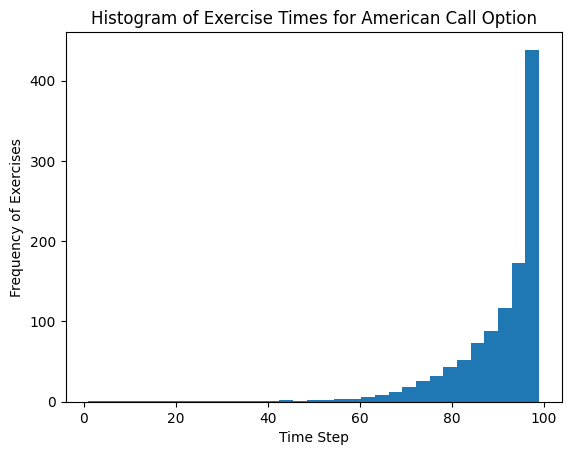

Percentage of paths with early exercise: 11.11%


In [17]:

n_paths = 10000
M = 1000

# Perform the simulation and analysis
percentage_early_exercise = simulate_and_analyze_exercise_times(S0, r, q, sigma, T, K, n_paths, n_steps, M)

print(f"Percentage of paths with early exercise: {percentage_early_exercise:.2f}%")

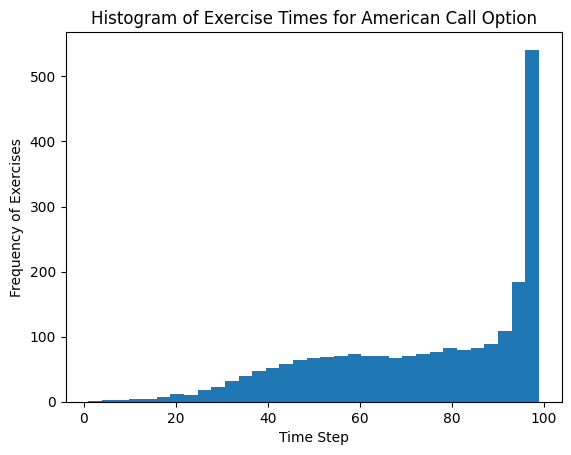

Percentage of paths with early exercise: 22.48%


In [18]:

# Perform the simulation and analysis
percentage_early_exercise = simulate_and_analyze_exercise_times(S0, r, q, 0.5, T, K, n_paths, n_steps, M)

print(f"Percentage of paths with early exercise: {percentage_early_exercise:.2f}%")


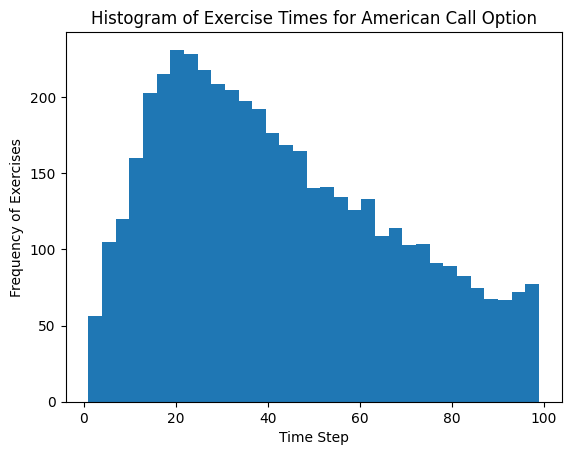

Percentage of paths with early exercise: 45.77%


In [19]:

# Perform the simulation and analysis
percentage_early_exercise = simulate_and_analyze_exercise_times(S0, r, q, 1.0, T, K, n_paths, n_steps, M)

print(f"Percentage of paths with early exercise: {percentage_early_exercise:.2f}%")


How does the percentage of paths where the option is exercised before maturity and the histogram of when
the option is exercised depend on the volatility?

In [20]:

# Function to perform LSM for different volatilities and tracxk exercise times
def exercise_time_analysis(volatilities, n_paths, n_steps, B=10, option_type='call', deg=2, typ='polynomial'):
    """
    Analyzes the impact of different volatilities on the exercise times of an American option using
    the Longstaff-Schwartz Least Squares Monte Carlo simulation.

    Parameters:
        volatilities (list): List of volatility values to analyze.
        n_paths (int): Number of paths to simulate for each Monte Carlo batch.
        n_steps (int): Number of time steps in each simulated path.
        B (int): Number of batches to simulate for each volatility to get statistically significant results. Default is 10.
        option_type (str): The type of option ('call' or 'put'). Default is 'call'.
        deg (int): Degree of the polynomial used in regression for continuation values. Default is 2.
        typ (str): The regression model type, typically 'polynomial'. Default is 'polynomial'.

    Returns:
        tuple: Returns two dictionaries, 
               - `exercise_results`: Maps each volatility to the average percentage of paths exercised before maturity.
               - `variances`: Maps each volatility to the variance in the percentage of early exercises.
    """
    # Dictionary to store the average percentage of exercises before maturity for each volatility
    exercise_results = {}
    # Dictionary to store the variance of exercise percentages for each volatility
    variances = {}

    # Iterate over each volatility in the provided list
    for vol in volatilities:
        # Initialize a matrix to store exercise times for all batches for this volatility
        all_exercise_times = np.zeros((B, n_paths))
        
        # Perform B Monte Carlo simulations for the current volatility
        for b in range(B):
            # Simulate paths and calculate exercise times using LSM
            _, exercise_times = longstaff_schwartz_lsm(
                simulate_paths_antithetic(S0, r, q, vol, T, n_steps, n_paths),
                K, r, T, n_steps, option_type=option_type, poly_degree=deg, poly_type=typ
            )
            # Store the exercise times for this batch
            all_exercise_times[b] = exercise_times

        # Calculate the percentage of paths that exercise before maturity for each batch
        percentage_exercised_before_maturity = np.mean(all_exercise_times < n_steps, axis=1) * 100
        # Store the average percentage of early exercises for this volatility
        exercise_results[vol] = np.mean(percentage_exercised_before_maturity)
        # Store the variance of early exercise percentages for this volatility
        variances[vol] = np.var(percentage_exercised_before_maturity)
    
    return exercise_results, variances


In [21]:

n_paths = 10000
n_steps = 100

# Volatilities to test
volatilities_to_test = np.linspace(0.1, 1, 10)

# Perform analysis for different volatilities
exercise_time_results, exercise_time_variances = exercise_time_analysis(volatilities_to_test, n_paths, n_steps, B=100, option_type='call')


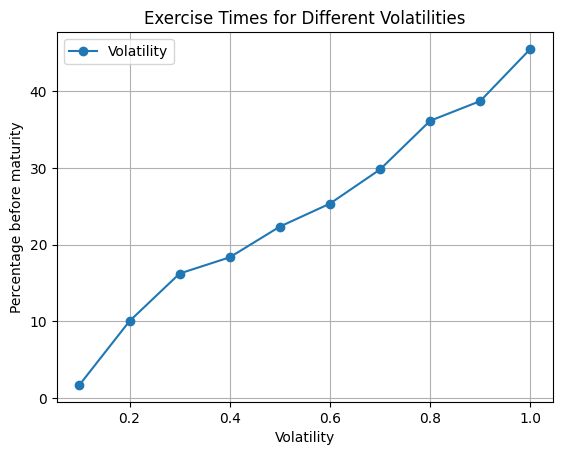

Volatility: 0.10   Percentage: 1.68    Variance: 10.77
Volatility: 0.20   Percentage: 10.02   Variance: 51.93
Volatility: 0.30   Percentage: 16.22   Variance: 42.20
Volatility: 0.40   Percentage: 18.34   Variance: 36.20
Volatility: 0.50   Percentage: 22.35   Variance: 69.22
Volatility: 0.60   Percentage: 25.35   Variance: 77.12
Volatility: 0.70   Percentage: 29.81   Variance: 106.86
Volatility: 0.80   Percentage: 36.16   Variance: 165.79
Volatility: 0.90   Percentage: 38.74   Variance: 182.11
Volatility: 1.00   Percentage: 45.54   Variance: 147.97


In [22]:

# Plotting for each volatility
plt.plot(volatilities_to_test, exercise_time_results.values(), '-o', label=f'Volatility')
plt.title('Exercise Times for Different Volatilities')
plt.xlabel('Volatility')
plt.ylabel('Percentage before maturity')
plt.legend()
plt.grid()
plt.savefig('plots/percentage_plot')
plt.show()

# Display exercise time results and variances
for vol, (res, var) in zip(volatilities_to_test, zip(exercise_time_results.values(), exercise_time_variances.values())):
    print(f"Volatility: {vol:<6.2f} Percentage: {res:<7.2f} Variance: {var:.2f}")


## Discrete dividends

In [23]:

def plot_priced_tree(stock_prices, forward_prices, option_prices, exercise_flags, scale=1, loc=0.6):
    """
    Visualizes a binomial tree for option pricing, displaying stock prices, forward prices,
    option prices, and exercise flags.

    Parameters:
        stock_prices (ndarray): A 2D array where each row represents a time step and each column
                                represents a possible stock price at that step in the binomial tree.
        forward_prices (ndarray): A 2D array of forward prices corresponding to each node in the
                                  binomial tree, structured like stock_prices.
        option_prices (ndarray): A 2D array of option prices at each node in the binomial tree.
        exercise_flags (ndarray): A 2D boolean array indicating whether exercising the option
                                  at each node is optimal.
        scale (float): A scaling factor for the size of the plot. Default is 1.
        loc (float): Location parameter for annotations, determining their horizontal position
                     relative to the node. Default is 0.6.

    Returns:
        None. Displays a plot of the binomial tree.
    """
    n_periods = stock_prices.shape[1]
    plt.figure(figsize=(1.2*n_periods*scale, 0.8*n_periods*scale))

    # Plot settings
    base_text_kwargs = dict(ha='center', va='center', fontsize=8)
    bbox_props = dict(fc="white", ec="white", lw=0.5)

    # Draw the nodes
    for t in range(n_periods):
        for i in range(t+1):
            s = stock_prices[i, t]
            f = forward_prices[i, t]
            op = option_prices[i, t]
            
            # Calculate the positions of the nodes
            x = t
            y = n_periods/2 - 2 * (i - t / 2) - 3
            
            
            # Node text for stock and forward prices
            sf_text = f"${s:.2f}\n$F^P$={f:.2f}"
            plt.text(x, y, sf_text, bbox=bbox_props, **base_text_kwargs)

            # Check if it's an exercise node and set bold for option price if needed
            if exercise_flags is not None and exercise_flags[i, t]:
                plt.text(x, y - loc/scale, f"${op:.2f}", fontweight='bold', bbox=bbox_props, **base_text_kwargs)
            else:
                plt.text(x, y - loc/scale, f"${op:.2f}", bbox=bbox_props, **base_text_kwargs)
            
            # Draw lines to the next nodes if not at the last period
            if t < n_periods - 1:
                next_y_up = y + 1
                next_y_down = y - 1
                # Up move line
                plt.plot([x, x+1], [y, next_y_up], 'k-', lw=0.5)
                # Down move line
                plt.plot([x, x+1], [y, next_y_down], 'k-', lw=0.5)

    # Formatting the plot
    plt.xlabel('Time Steps')
    plt.ylabel('Nodes')
    plt.xticks(range(n_periods))
    plt.yticks([2 * (i - n_periods / 2) for i in range(n_periods)])
    plt.grid(False)
    plt.axis(False)
    plt.savefig(f'plots/binmoial_tree_{n_periods-1}')
    plt.show()

def option_binomial_pre_paid(S0, K, T, r, q, sigma, n, D, TD, option_type='call', option_style='european', tree=False):
    """
    Calculates the price of an American or European option using a binomial tree model that accounts
    for a pre-paid dividend.

    Parameters:
        S0 (float): Initial stock price.
        K (float): Strike price of the option.
        T (float): Time to maturity of the option, in years.
        r (float): Risk-free interest rate, annualized.
        q (float): Continuous dividend yield.
        sigma (float): Volatility of the underlying stock.
        n (int): Number of steps in the binomial tree.
        D (float): Dividend amount.
        TD (float): Time until dividend payment, in years.
        option_type (str): Type of the option ('call' or 'put').
        option_style (str): Style of the option ('european' or 'american').
        tree (bool): If True, returns the entire tree of stock prices, forward prices, option prices, and exercise flags.

    Returns:
        If tree is True, returns a tuple of numpy arrays (S, FP, option, exercise).
        Otherwise, returns the option price at time zero.
    """
    # Time step
    dt = T / n  

    # Initialize matrices for the stock price, forward price, and option price
    S = np.zeros((n + 1, n + 1))
    FP = np.zeros((n + 1, n + 1))
    option = np.zeros((n + 1, n + 1))
    exercise = np.full((n + 1, n + 1), False)

    # Initial stock and forward price accounting for the prepaid dividend
    S[0, 0] = S0
    FP[0, 0] = S0 - D * np.exp(-r * TD)  # Forward price adjusted for discounted dividend

    # Adjust volatility for forward pricing
    sigma_F = sigma * S[0, 0] / FP[0, 0]

    # Calculate up and down factors
    u = np.exp((r - q) * dt + sigma_F * np.sqrt(dt))  
    d = np.exp((r - q) * dt - sigma_F * np.sqrt(dt))  
    # Risk-neutral probability
    p = (np.exp((r - q) * dt) - d) / (u - d)  

    # Generate binomial tree for forward and stock prices
    for i in range(1, n + 1):
        for j in range(i + 1):
            FP[j, i] = FP[0, 0] * (d ** j) * (u ** (i - j))
            S[j, i] = FP[j, i]
            # Adjust stock price for the time of the dividend payment
            if i * dt <= TD:
                S[j, i] += D * np.exp(-r * (TD - i * dt))

    # Initialize option values at maturity
    if option_type == 'call':
        option[:, n] = np.maximum(S[:, n] - K, 0)
    elif option_type == 'put':
        option[:, n] = np.maximum(K - S[:, n], 0)

    # Backward calculation through the tree to determine early exercise and option values
    for i in range(n - 1, -1, -1):
        for j in range(i + 1):
            continuation_value = np.exp(-r * dt) * (p * option[j, i + 1] + (1 - p) * option[j + 1, i + 1])
            if option_style == 'american':
                if option_type == 'call':
                    option[j, i] = max(S[j, i] - K, continuation_value)
                else:  # Put
                    option[j, i] = max(K - S[j, i], continuation_value)
            else:  # European style, no early exercise
                option[j, i] = continuation_value

    # Determine if exercising at each node is optimal, useful for American options
    for i in range(n, -1, -1):
        for j in range(i + 1):
            exercise_value = (S[j, i] - K if option_type == 'call' else K - S[j, i])
            exercise[j, i] = option[j, i] == exercise_value

    # Return the full tree data if requested
    if tree:
        return S, FP, option, exercise
    # Otherwise, return just the current option price
    return option[0, 0]


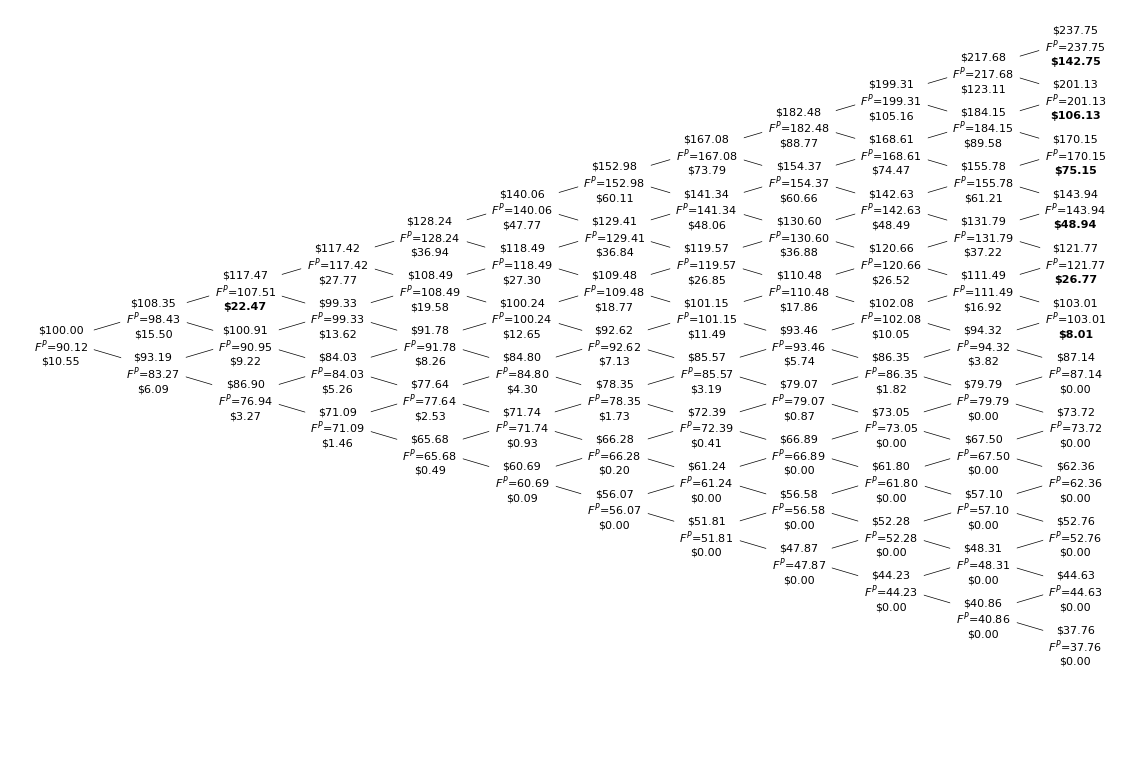

10.551384780386577


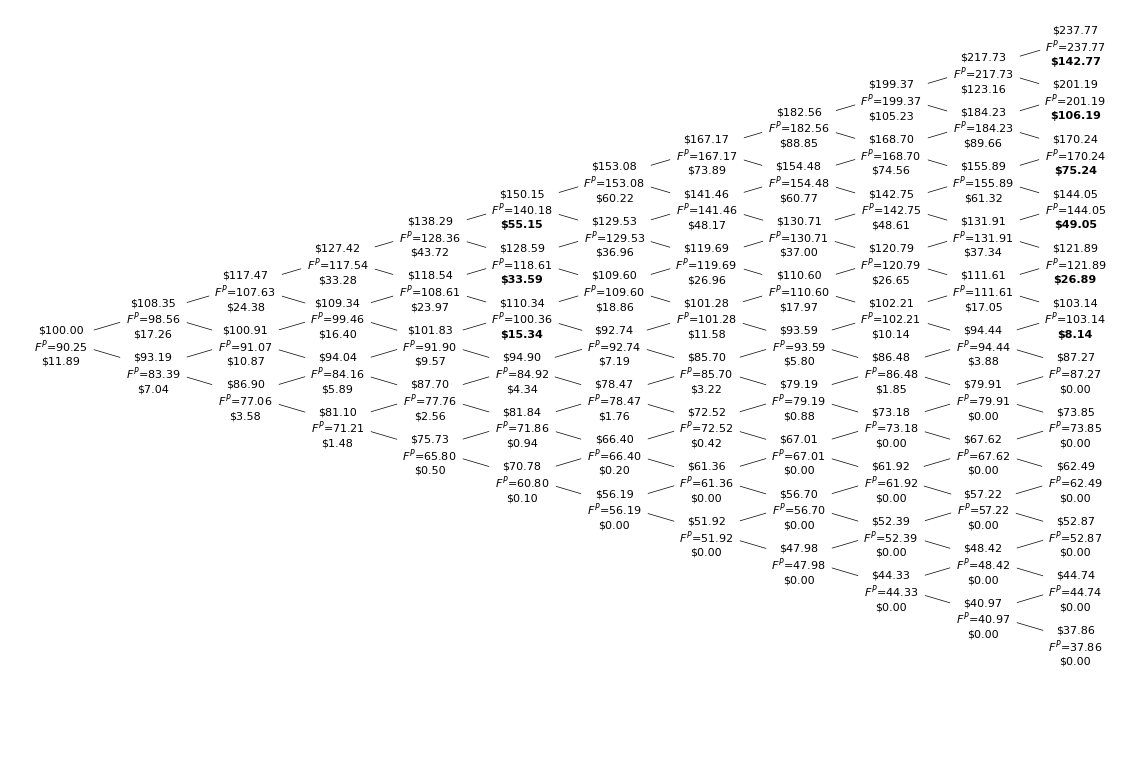

11.885360027962603


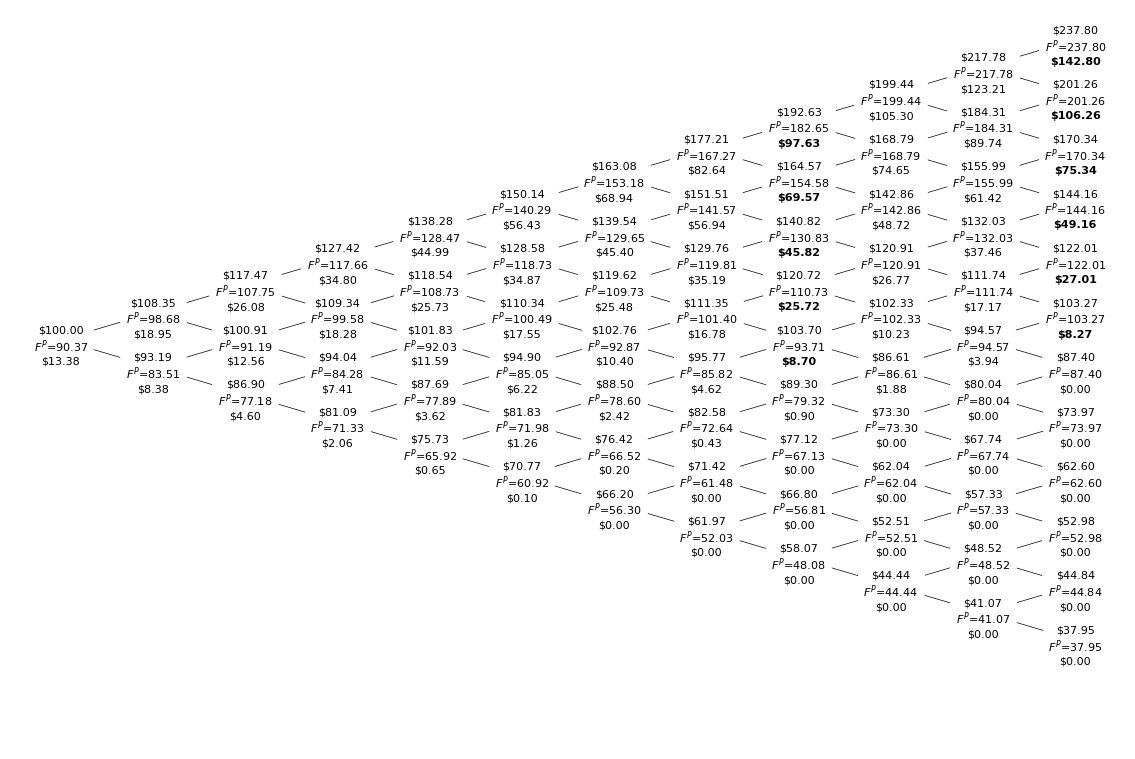

13.383371856093937


In [24]:

S0 = 100  # Initial stock price
K = 95  # Strike price
T = 1  # Time to maturity
r = 0.05  # Risk-free rate
q = 0.00  # Dividend yield
sigma = 0.25  # Volatility of the underlying asset
D = 10  # Discrete dividend amount
TDs = [3/12, 6/12, 9/12]  # Time when dividend is paid
n = 11  # Number of periods

# Recalculate the binomial tree with the dividend adjustment
for TD in TDs:
    S, FP, option, exercise = option_binomial_pre_paid(S0, K, T, r, q, sigma, n, D, TD, option_type='call', option_style='american', tree=True)
    plot_priced_tree(S, FP, option, exercise, scale=1, loc=0.8)
    print(option[0, 0])


In [25]:

TDs = np.linspace(1/12, 11/12, 11)  # Time when dividend is paid

# Recalculate the binomial tree with the dividend adjustment
for TD in TDs:
    option_price = option_binomial_pre_paid(S0, K, T, r, q, sigma, n, D, TD, option_type='call', option_style='american', tree=False)
    print(option_price)

10.022629278552964
10.041020449069375
10.551384780386577
10.82491871007939
11.299174468446928
11.885360027962603
12.167957952492365
12.817197003869042
13.383371856093937
13.663576226080936
14.512423136719935
